# 02 – Results: model comparison, errors and ROC curves

This notebook uses the code in `src/` to show the results. The heavy lifting (data cleaning, pipeline, cross-validation, tuning) lives in `src/`; here we only look at the outputs.

All numbers come from **cross-validation on the 302 unique patients**. There is no separate test set (see the limitations section in the README).

In [1]:
import sys
sys.path.append("..")

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_predict

from src.data import load_clean
from src.evaluate import CV
from src.tune import SEARCHES, make_search

warnings.filterwarnings("ignore", category=ConvergenceWarning)

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# One fixed colour per model (same order everywhere)
COLORS = {"Logistic Regression": "#2a78d6", "Random Forest": "#eb6834",
          "SVM (RBF kernel)": "#1baf7a", "XGBoost": "#eda100"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "axes.axisbelow": True})

X, y = load_clean()

## 1. Cross-validation results

Saved by `python -m src.compare_models` (default settings) and `python -m src.tune` (tuned with nested CV). Mean ± standard deviation over the 5 outer test folds.

In [2]:
def as_table(path):
    df = pd.read_csv(path, index_col="model")
    table = pd.DataFrame(index=df.index)
    for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        table[m] = [f"{a:.3f} ± {s:.3f}" for a, s in zip(df[f"{m}_mean"], df[f"{m}_std"])]
    table["train acc."] = df["train_accuracy"].round(3)
    return table

print("Default settings:")
display(as_table("../reports/cv_results_default.csv"))
print("Tuned (nested CV):")
display(as_table("../reports/cv_results_tuned.csv"))

Default settings:


,accuracy,precision,recall,f1,roc_auc,train acc.
model,,,,,,
Baseline (always 'no disease'),0.543 ± 0.007,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.543
Logistic Regression,0.848 ± 0.028,0.868 ± 0.095,0.804 ± 0.077,0.829 ± 0.024,0.917 ± 0.025,0.876
Random Forest,0.815 ± 0.035,0.807 ± 0.053,0.790 ± 0.087,0.795 ± 0.043,0.907 ± 0.017,1.000
SVM (RBF kernel),0.835 ± 0.019,0.865 ± 0.065,0.768 ± 0.094,0.808 ± 0.032,0.907 ± 0.024,0.911
XGBoost,0.805 ± 0.044,0.797 ± 0.059,0.776 ± 0.067,0.784 ± 0.045,0.878 ± 0.022,1.000


Tuned (nested CV):


,accuracy,precision,recall,f1,roc_auc,train acc.
model,,,,,,
Logistic Regression,0.854 ± 0.019,0.887 ± 0.078,0.797 ± 0.075,0.833 ± 0.017,0.920 ± 0.019,0.873
Random Forest,0.831 ± 0.030,0.851 ± 0.080,0.783 ± 0.072,0.809 ± 0.028,0.918 ± 0.012,0.878
SVM (RBF kernel),0.854 ± 0.033,0.903 ± 0.093,0.783 ± 0.072,0.831 ± 0.033,0.920 ± 0.017,0.873
XGBoost,0.835 ± 0.033,0.850 ± 0.073,0.790 ± 0.089,0.812 ± 0.041,0.905 ± 0.019,0.900


**Final model: Logistic Regression.** It is tied with the SVM for the best accuracy and ROC-AUC, and the difference to the other models is within the fold-to-fold noise. I chose it because it is the simplest, its tuned setting was stable (C = 0.1 in 4 of 5 folds), it gives probabilities directly, and its weights can be explained.

## 2. Out-of-fold predictions

To draw a confusion matrix and ROC curve from cross-validation, I use `cross_val_predict`. It returns, for every patient, the prediction made by the model that was **not** trained on that patient (the patient was in that fold's test set). Each model is still tuned with GridSearchCV inside each fold, exactly as in `src/tune.py`.

For Logistic Regression, Random Forest and XGBoost the score is the predicted probability of disease. The SVM has no probabilities by default, so its score is the distance from the decision boundary. ROC curves only need the *ranking* of patients, so both work.

In [3]:
oof_scores = {}
for name, (model, grid) in SEARCHES.items():
    method = "decision_function" if name.startswith("SVM") else "predict_proba"
    pred = cross_val_predict(make_search(model, grid), X, y, cv=CV, method=method)
    oof_scores[name] = pred[:, 1] if method == "predict_proba" else pred
    print(f"{name:20s} done")

FINAL = "Logistic Regression"
proba = oof_scores[FINAL]   # out-of-fold probability of disease for each patient

Logistic Regression  done


Random Forest        done


SVM (RBF kernel)     done


XGBoost              done


## 3. Confusion matrix (final model, cut-off 0.5)

The model predicts "disease" when the probability is at least 0.5.

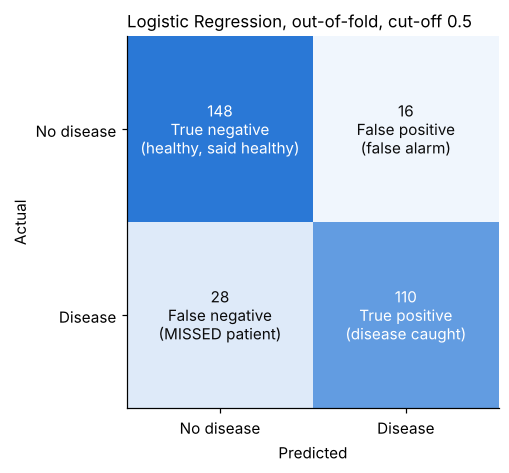

Disease patients: 138.  Caught: 110.  Missed: 28.  Recall = 0.797
Flagged as disease: 126.  Correct: 110.  False alarms: 16.  Precision = 0.873


In [4]:
y_pred = (proba >= 0.5).astype(int)
cm = confusion_matrix(y, y_pred)
tn, fp, fn, tp = cm.ravel()

blues = LinearSegmentedColormap.from_list("blues", ["#f0f6fd", "#2a78d6"])
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm, cmap=blues)
ax.grid(False)
names = [["True negative\n(healthy, said healthy)", "False positive\n(false alarm)"],
         ["False negative\n(MISSED patient)", "True positive\n(disease caught)"]]
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "#0b0b0b"
        ax.text(j, i, f"{cm[i, j]}\n{names[i][j]}", ha="center", va="center",
                fontsize=10, color=color)
ax.set_xticks([0, 1], ["No disease", "Disease"])
ax.set_yticks([0, 1], ["No disease", "Disease"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Logistic Regression, out-of-fold, cut-off 0.5", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Disease patients: {tp + fn}.  Caught: {tp}.  Missed: {fn}.  Recall = {tp / (tp + fn):.3f}")
print(f"Flagged as disease: {tp + fp}.  Correct: {tp}.  False alarms: {fp}.  Precision = {tp / (tp + fp):.3f}")

These pooled numbers are close to, but not exactly, the fold averages in the table above (there we averaged 5 fold scores; here all 302 predictions are counted together).

## 4. ROC curves

An ROC curve shows every possible cut-off at once: for each cut-off, how many sick patients are caught (true positive rate = recall) against how many healthy patients get a false alarm (false positive rate). The closer the curve is to the top-left corner, the better. The dashed diagonal is random guessing (AUC = 0.5).

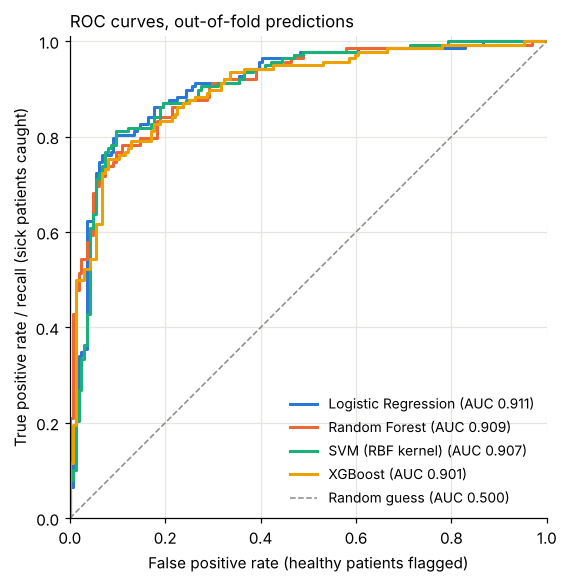

In [5]:
fig, ax = plt.subplots(figsize=(6, 5.4))
for name, scores in oof_scores.items():
    fpr, tpr, _ = roc_curve(y, scores)
    auc = roc_auc_score(y, scores)
    ax.plot(fpr, tpr, linewidth=2, color=COLORS[name], label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="#8a8984", linewidth=1, label="Random guess (AUC 0.500)")
ax.set_xlabel("False positive rate (healthy patients flagged)")
ax.set_ylabel("True positive rate / recall (sick patients caught)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.set_aspect("equal")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_title("ROC curves, out-of-fold predictions", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

The four curves lie almost on top of each other, which matches the table: on this data the choice of model matters much less than the size of the data.

The AUC values in the legend (e.g. 0.911 for Logistic Regression) are a little lower than the table (0.920). The table averages the AUC of each fold separately; the plot pools all 302 out-of-fold predictions into one curve. Pooling mixes scores from 5 slightly different models, which usually lowers AUC a little. Both are valid; the README reports the fold average.

## 5. Choosing the cut-off: recall vs false alarms

With the default cut-off of 0.5, the model misses some sick patients. In screening, a missed patient is usually worse than a false alarm, so one option is to lower the cut-off. The table shows the trade-off.

In [6]:
rows = []
for cut in [0.5, 0.4, 0.3, 0.2]:
    pred = (proba >= cut).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y, pred).ravel()
    rows.append({"cut-off": cut,
                 "recall": round(tp_ / (tp_ + fn_), 3),
                 "precision": round(tp_ / (tp_ + fp_), 3),
                 "missed patients (FN)": fn_,
                 "false alarms (FP)": fp_,
                 "accuracy": round((tp_ + tn_) / len(y), 3)})
pd.DataFrame(rows).set_index("cut-off")

,recall,precision,missed patients (FN),false alarms (FP),accuracy
cut-off,,,,,
0.5,0.797,0.873,28,16,0.854
0.4,0.841,0.806,22,28,0.834
0.3,0.913,0.724,12,48,0.801
0.2,0.964,0.646,5,73,0.742


Lowering the cut-off catches more sick patients but creates more false alarms. Which cut-off is "right" is a clinical decision about costs, not something the data can decide. Also, I picked these cut-offs while looking at the same cross-validation predictions, so the numbers for a lower cut-off are a rough guide, not a validated result.

**What I do in this project:** the Flask app returns the **probability**, not only a yes/no, and keeps the standard 0.5 cut-off for the label. A real screening tool would need its cut-off chosen with clinicians and checked on new patients.